In [1]:
!pip install -q timm torch torchvision matplotlib opencv-python scikit-learn pandas
# Run this if needed: !pip install jupyter

In [2]:
import os
import glob
import cv2
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [3]:
class BlastocystDataset(Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform
        self.labels, self.classes = self._extract_labels()

    def _extract_labels(self):
        labels = []
        for path in self.image_paths:
            filename = os.path.basename(path)
            # Assuming grade is specified in filename like 'AA', 'AB', 'AC'
            # Using regex to find 2 consecutive uppercase letters (Adjust if format is different)
            match = re.search(r'([A-Z]{2})', filename)
            grade = match.group(1) if match else "UNKNOWN"
            labels.append(grade)

        classes = sorted(list(set(labels)))
        # Filter out unknown if needed, or handle mapping
        self.class_to_idx = {c: i for i, c in enumerate(classes)}
        idx_labels = [self.class_to_idx[l] for l in labels]
        return idx_labels, classes

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image)

        label = self.labels[idx]

        return image, label

In [4]:
from google.colab import drive
drive.mount('/content/drive')

train_dir = "/content/drive/MyDrive/Project/train"
print("Train directory exists:", os.path.exists(train_dir))
print("Train directory:", train_dir)

all_files = []

for root, dirs, files in os.walk(train_dir):
    for file in files:
        all_files.append(os.path.join(root, file))

print("Total files found:", len(all_files))

print("\nFirst 20 files:")
for f in all_files[:20]:
    print(f)

Mounted at /content/drive
Train directory exists: True
Train directory: /content/drive/MyDrive/Project/train
Total files found: 113

First 20 files:
/content/drive/MyDrive/Project/train/GRD_BA_455.jpeg
/content/drive/MyDrive/Project/train/GRD_BA_456.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_557 (1).jpeg
/content/drive/MyDrive/Project/train/GRD_AA_558.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_554.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_555.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_463.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_464.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_425.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_426.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_455.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_456.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_556.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_557.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_416.jpeg
/content/drive/MyDrive/Project/train/GRD_AA_417 (1).

In [5]:
import os
import glob
import re

data_dir = "/content/drive/MyDrive/Project"
# Find all images recursively
extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')

train_paths = []
test_paths = []

for ext in extensions:
    train_paths.extend(
        glob.glob(os.path.join(data_dir, 'train', '**', ext), recursive=True)
    )
    test_paths.extend(
        glob.glob(os.path.join(data_dir, 'test', '**', ext), recursive=True)
    )

print(f"Found {len(train_paths)} training images")
print(f"Found {len(test_paths)} testing images")

def extract_grade(path):
    filename = os.path.basename(path)

    # 1. Try to match standard format with underscore or hyphen (e.g., GRD_AA_..., GRD-AA-...)
    match = re.search(r'^GRD[-_]([A-Z]{2})[-_]', filename)
    if match:
        return match.group(1)

    # 2. Fallback: Search for any 2-letter uppercase grade pattern (AA, AB, BA, BB, BC, CA, CB) in the filename
    match_any = re.search(r'(AA|AB|BA|BB|BC|CA|CB)', filename)
    if match_any:
        return match_any.group(1)

    return None

# Check a few
for path in train_paths[:20]:
    print(os.path.basename(path), "->", extract_grade(path))

Found 113 training images
Found 29 testing images
GRD_BA_455.jpeg -> BA
GRD_BA_456.jpeg -> BA
GRD_AA_557 (1).jpeg -> AA
GRD_AA_558.jpeg -> AA
GRD_AA_554.jpeg -> AA
GRD_AA_555.jpeg -> AA
GRD_AA_463.jpeg -> AA
GRD_AA_464.jpeg -> AA
GRD_AA_425.jpeg -> AA
GRD_AA_426.jpeg -> AA
GRD_AA_455.jpeg -> AA
GRD_AA_456.jpeg -> AA
GRD_AA_556.jpeg -> AA
GRD_AA_557.jpeg -> AA
GRD_AA_416.jpeg -> AA
GRD_AA_417 (1).jpeg -> AA
GRD_AA_547 (1).jpeg -> AA
GRD_AA_548 (2).jpeg -> AA
GRD_AA_552 (2).jpeg -> AA
GRD_AA_553 (1).jpeg -> AA


In [6]:
# Define transforms
train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load paths
#data_dir = 'D:\VSCODE\Maatru samarpan\data'
train_paths = glob.glob(os.path.join(data_dir, 'train', '*.*'))
test_paths = glob.glob(os.path.join(data_dir, 'test', '*.*'))

# If test dir is empty, split train
if len(test_paths) == 0 and len(train_paths) > 0:
    print("Splitting train into train/val because test is empty")
    train_paths, test_paths = train_test_split(train_paths, test_size=0.2, random_state=42)

print(f"Found {len(train_paths)} training images and {len(test_paths)} testing images.")

if len(train_paths) > 0:
    train_dataset = BlastocystDataset(train_paths, transform=train_transforms)
    test_dataset = BlastocystDataset(test_paths, transform=test_transforms)

    num_classes = len(train_dataset.classes)
    print(f"Classes found: {train_dataset.classes}")

    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)


Found 113 training images and 29 testing images.
Classes found: ['AA', 'AB', 'BA', 'BB', 'BC', 'GR']


In [7]:
print("TRAIN mapping:")
print(train_dataset.class_to_idx)

print("\nTEST mapping:")
print(test_dataset.class_to_idx)

print("\nTRAIN classes:")
print(train_dataset.classes)

print("\nTEST classes:")
print(test_dataset.classes)

TRAIN mapping:
{'AA': 0, 'AB': 1, 'BA': 2, 'BB': 3, 'BC': 4, 'GR': 5}

TEST mapping:
{'GR': 0}

TRAIN classes:
['AA', 'AB', 'BA', 'BB', 'BC', 'GR']

TEST classes:
['GR']


In [8]:
import os
import glob
import re

data_dir = "/content/drive/MyDrive/Project"

extensions = (
    '*.jpg', '*.jpeg', '*.png',
    '*.JPG', '*.JPEG', '*.PNG'
)

train_paths = []
test_paths = []

for ext in extensions:

    train_paths.extend(
        glob.glob(
            os.path.join(data_dir, 'train', '**', ext),
            recursive=True
        )
    )

    test_paths.extend(
        glob.glob(
            os.path.join(data_dir, 'test', '**', ext),
            recursive=True
        )
    )

print("Train images:", len(train_paths))
print("Test images :", len(test_paths))

Train images: 113
Test images : 29


In [9]:
from collections import Counter

train_grades = [
    extract_grade(p)
    for p in train_paths
]

test_grades = [
    extract_grade(p)
    for p in test_paths
]

print("TRAIN:")
print(Counter(train_grades))

print("\nTEST:")
print(Counter(test_grades))

print("\nALL CLASSES:")
print(sorted(list(set(train_grades + test_grades))))

TRAIN:
Counter({'AA': 76, 'BB': 17, 'BA': 12, 'AB': 6, 'BC': 2})

TEST:
Counter({'BB': 13, 'BC': 6, 'CB': 4, 'AA': 2, 'BA': 2, 'CA': 2})

ALL CLASSES:
['AA', 'AB', 'BA', 'BB', 'BC', 'CA', 'CB']


In [10]:
# Let's see which files returned None to understand their patterns
print("--- Train files that returned None ---")
none_train = [p for p in train_paths if extract_grade(p) is None]
for p in none_train[:10]:
    print(os.path.basename(p))
print(f"Total None in Train: {len(none_train)}")

print("\n--- Test files that returned None ---")
none_test = [p for p in test_paths if extract_grade(p) is None]
for p in none_test[:10]:
    print(os.path.basename(p))
print(f"Total None in Test: {len(none_test)}")

--- Train files that returned None ---
Total None in Train: 0

--- Test files that returned None ---
Total None in Test: 0


In [11]:
import os
import glob
import re
from collections import Counter

# All images from both train and test
all_paths = train_paths + test_paths

def extract_raw_grade(path):
    filename = os.path.basename(path)
    name = os.path.splitext(filename)[0]

    # GRD_AA_561
    # GRD-AA-564
    match = re.match(r'^GRD[-_]([A-Z]{2})[-_]', name)

    if match:
        return match.group(1)

    # AA.jpeg
    # AA (1).jpeg
    # AB (2).jpeg
    match = re.match(r'^([A-Z]{2})(?: \(\d+\))?$', name)

    if match:
        return match.group(1)

    return None


raw_grades = [
    extract_raw_grade(path)
    for path in all_paths
]

print("Total images:", len(all_paths))

print("\n=== ALL DETECTED LABELS ===")
print(Counter(raw_grades))

print("\n=== UNIQUE LABELS ===")
print(sorted(set(g for g in raw_grades if g is not None)))

print("\n=== UNRECOGNIZED FILES ===")
for path, grade in zip(all_paths, raw_grades):
    if grade is None:
        print(os.path.basename(path))

Total images: 142

=== ALL DETECTED LABELS ===
Counter({'AA': 78, 'BB': 30, 'BA': 14, 'BC': 8, 'AB': 6, 'CB': 4, 'CA': 2})

=== UNIQUE LABELS ===
['AA', 'AB', 'BA', 'BB', 'BC', 'CA', 'CB']

=== UNRECOGNIZED FILES ===


In [12]:
from collections import Counter

train_grades = [extract_grade(p) for p in train_paths]
test_grades = [extract_grade(p) for p in test_paths]

print("TRAIN:")
print(Counter(train_grades))

print("\nTEST:")
print(Counter(test_grades))

print("\nAll classes:")
print(sorted(set(train_grades + test_grades)))

TRAIN:
Counter({'AA': 76, 'BB': 17, 'BA': 12, 'AB': 6, 'BC': 2})

TEST:
Counter({'BB': 13, 'BC': 6, 'CB': 4, 'AA': 2, 'BA': 2, 'CA': 2})

All classes:
['AA', 'AB', 'BA', 'BB', 'BC', 'CA', 'CB']


In [13]:
from collections import Counter

print("\nTrain label distribution:")
print(Counter(extract_grade(p) for p in train_paths))

print("\nTest label distribution:")
print(Counter(extract_grade(p) for p in test_paths))


Train label distribution:
Counter({'AA': 76, 'BB': 17, 'BA': 12, 'AB': 6, 'BC': 2})

Test label distribution:
Counter({'BB': 13, 'BC': 6, 'CB': 4, 'AA': 2, 'BA': 2, 'CA': 2})


In [14]:
print("TRAIN FILES WITH NO LABEL:")
for p in train_paths:
    if extract_grade(p) is None:
        print(os.path.basename(p))

TRAIN FILES WITH NO LABEL:


In [15]:
VALID_CLASSES = ['AA', 'AB', 'BA', 'BB', 'BC', 'CA', 'CB']

class_to_idx = {
    grade: idx
    for idx, grade in enumerate(VALID_CLASSES)
}

idx_to_class = {
    idx: grade
    for grade, idx in class_to_idx.items()
}

print(class_to_idx)

{'AA': 0, 'AB': 1, 'BA': 2, 'BB': 3, 'BC': 4, 'CA': 5, 'CB': 6}


In [16]:
def extract_grade(path):
    filename = os.path.basename(path)
    name = os.path.splitext(filename)[0]

    # GRD_AA_561 / GRD-AA-564
    match = re.match(r'^GRD[-_]([A-Z]{2})[-_]', name)

    if match:
        grade = match.group(1)
        return grade if grade in VALID_CLASSES else None

    # AA / AA (1) / AB (3)
    match = re.match(r'^([A-Z]{2})(?: \(\d+\))?$', name)

    if match:
        grade = match.group(1)
        return grade if grade in VALID_CLASSES else None

    return None

In [17]:
from collections import Counter
from sklearn.model_selection import train_test_split

VALID_CLASSES = ['AA', 'AB', 'BA', 'BB', 'BC', 'CA', 'CB']

all_paths = train_paths + test_paths

valid_data = []

for path in all_paths:
    grade = extract_grade(path)

    if grade in VALID_CLASSES:
        valid_data.append((path, grade))

all_paths = [x[0] for x in valid_data]
all_labels = [x[1] for x in valid_data]

print("Total valid images:", len(all_paths))
print("Class distribution:")
print(Counter(all_labels))

Total valid images: 142
Class distribution:
Counter({'AA': 78, 'BB': 30, 'BA': 14, 'BC': 8, 'AB': 6, 'CB': 4, 'CA': 2})


In [18]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

print("Train:", len(train_paths))
print("Test :", len(test_paths))

print("\nTrain distribution:")
print(Counter(train_labels))

print("\nTest distribution:")
print(Counter(test_labels))

Train: 113
Test : 29

Train distribution:
Counter({'AA': 62, 'BB': 24, 'BA': 11, 'BC': 6, 'AB': 5, 'CB': 3, 'CA': 2})

Test distribution:
Counter({'AA': 16, 'BB': 6, 'BA': 3, 'BC': 2, 'AB': 1, 'CB': 1})


In [19]:
class_to_idx = {
    'AA': 0,
    'AB': 1,
    'BA': 2,
    'BB': 3,
    'BC': 4,
    'CA': 5,
    'CB': 6
}

idx_to_class = {
    v: k for k, v in class_to_idx.items()
}

num_classes = len(VALID_CLASSES)

print("Number of classes:", num_classes)
print("Mapping:", class_to_idx)

Number of classes: 7
Mapping: {'AA': 0, 'AB': 1, 'BA': 2, 'BB': 3, 'BC': 4, 'CA': 5, 'CB': 6}


In [20]:
class BlastocystDataset(Dataset):

    def __init__(self, image_paths, transform=None, class_to_idx=None):
        self.transform = transform
        self.image_paths = []
        self.labels = []

        for path in image_paths:

            grade = extract_grade(path)

            if grade in class_to_idx:
                self.image_paths.append(path)
                self.labels.append(grade)

        self.class_to_idx = class_to_idx
        self.classes = list(class_to_idx.keys())

        self.targets = [
            self.class_to_idx[label]
            for label in self.labels
        ]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image = Image.open(
            self.image_paths[idx]
        ).convert("RGB")

        label = self.targets[idx]

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(
            label,
            dtype=torch.long
        )

In [21]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [22]:
train_dataset = BlastocystDataset(
    train_paths,
    transform=train_transform,
    class_to_idx=class_to_idx
)

test_dataset = BlastocystDataset(
    test_paths,
    transform=test_transform,
    class_to_idx=class_to_idx
)

In [23]:
print("Train samples:", len(train_dataset))
print("Test samples :", len(test_dataset))

print("\nTrain labels:")
print(Counter(train_dataset.labels))

print("\nTest labels:")
print(Counter(test_dataset.labels))

Train samples: 113
Test samples : 29

Train labels:
Counter({'AA': 62, 'BB': 24, 'BA': 11, 'BC': 6, 'AB': 5, 'CB': 3, 'CA': 2})

Test labels:
Counter({'AA': 16, 'BB': 6, 'BA': 3, 'BC': 2, 'AB': 1, 'CB': 1})


In [24]:
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2
)

In [25]:
import torch
from collections import Counter

train_counts = Counter(train_dataset.labels)

class_weights = []

for cls in VALID_CLASSES:
    count = train_counts.get(cls, 0)

    weight = len(train_dataset) / (
        num_classes * count
    )

    class_weights.append(weight)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print(class_weights)

tensor([0.2604, 3.2286, 1.4675, 0.6726, 2.6905, 8.0714, 5.3810],
       device='cuda:0')


In [26]:
def get_vgg16(num_classes):
    model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    # Freeze early layers
    for param in model.features.parameters():
        param.requires_grad = False
    model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
    return model

def get_vit(num_classes):
    # Using timm to get pretrained ViT
    model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=num_classes)
    return model

def get_swin(num_classes):
    # Using timm to get pretrained Swin
    model = timm.create_model('swin_base_patch4_window7_224', pretrained=True, num_classes=num_classes)
    return model


In [27]:
def train_model(model, train_loader, test_loader, num_epochs=5, lr=1e-4):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr)

    history = {'train_loss': [], 'val_acc': []}

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)
        history['train_loss'].append(train_loss)

        # Validation
        val_acc, _, _ = evaluate_model(model, test_loader)
        history['val_acc'].append(val_acc)
        print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {train_loss:.4f}, Val Acc: {val_acc:.4f}")

    return model, history

def evaluate_model(model, data_loader):
    model.eval()
    model = model.to(device)
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    return acc, all_labels, all_preds


In [29]:
from PIL import Image, ImageFile

# Configure PIL to tolerate and load truncated/corrupted images
ImageFile.LOAD_TRUNCATED_IMAGES = True

if len(train_paths) > 0:
    results = {}

    print("Training VGG16...")
    vgg_model = get_vgg16(num_classes)
    vgg_model, vgg_history = train_model(vgg_model, train_loader, test_loader, num_epochs=100)
    results['VGG16'] = evaluate_model(vgg_model, test_loader)

    print("\nTraining ViT...")
    vit_model = get_vit(num_classes)
    vit_model, vit_history = train_model(vit_model, train_loader, test_loader, num_epochs=100)
    results['ViT'] = evaluate_model(vit_model, test_loader)

    print("\nTraining Swin Transformer...")
    swin_model = get_swin(num_classes)
    swin_model, swin_history = train_model(swin_model, train_loader, test_loader, num_epochs=100)
    results['Swin'] = evaluate_model(swin_model, test_loader)

Training VGG16...
Epoch [1/100] - Loss: 1.5800, Val Acc: 0.5517
Epoch [2/100] - Loss: 1.2039, Val Acc: 0.5517
Epoch [3/100] - Loss: 1.1408, Val Acc: 0.5862
Epoch [4/100] - Loss: 1.0989, Val Acc: 0.7241
Epoch [5/100] - Loss: 1.0276, Val Acc: 0.6897
Epoch [6/100] - Loss: 0.8335, Val Acc: 0.5862
Epoch [7/100] - Loss: 0.9258, Val Acc: 0.6897
Epoch [8/100] - Loss: 0.8143, Val Acc: 0.6552
Epoch [9/100] - Loss: 0.8316, Val Acc: 0.6552
Epoch [10/100] - Loss: 0.9203, Val Acc: 0.7586
Epoch [11/100] - Loss: 0.9252, Val Acc: 0.6552
Epoch [12/100] - Loss: 0.6646, Val Acc: 0.6552
Epoch [13/100] - Loss: 0.8077, Val Acc: 0.6897
Epoch [14/100] - Loss: 0.6843, Val Acc: 0.6897
Epoch [15/100] - Loss: 0.8662, Val Acc: 0.7241
Epoch [16/100] - Loss: 0.7371, Val Acc: 0.6897
Epoch [17/100] - Loss: 0.6527, Val Acc: 0.7241
Epoch [18/100] - Loss: 0.4686, Val Acc: 0.6897
Epoch [19/100] - Loss: 0.4419, Val Acc: 0.8276
Epoch [20/100] - Loss: 0.3483, Val Acc: 0.8276
Epoch [21/100] - Loss: 0.3833, Val Acc: 0.7931
Epoc

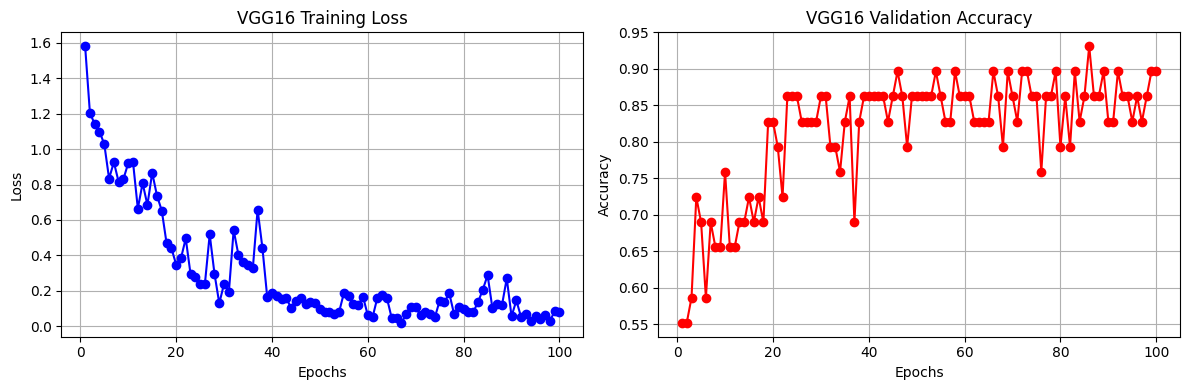

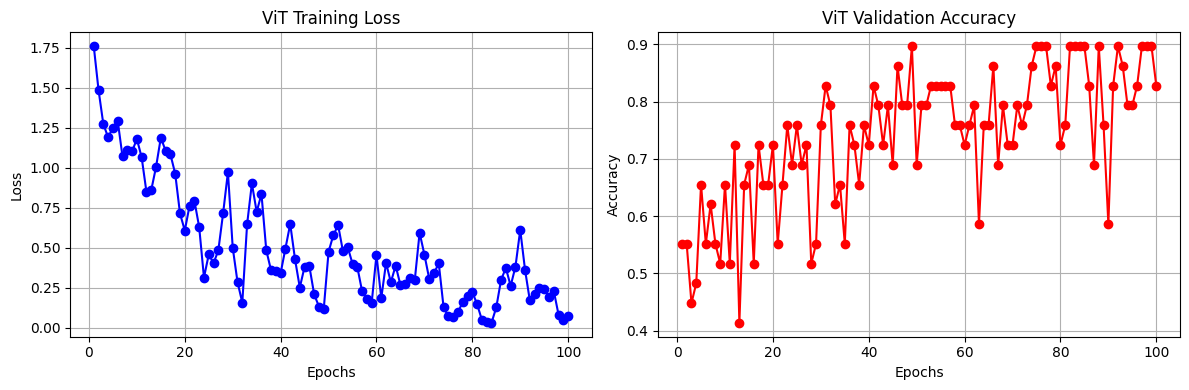

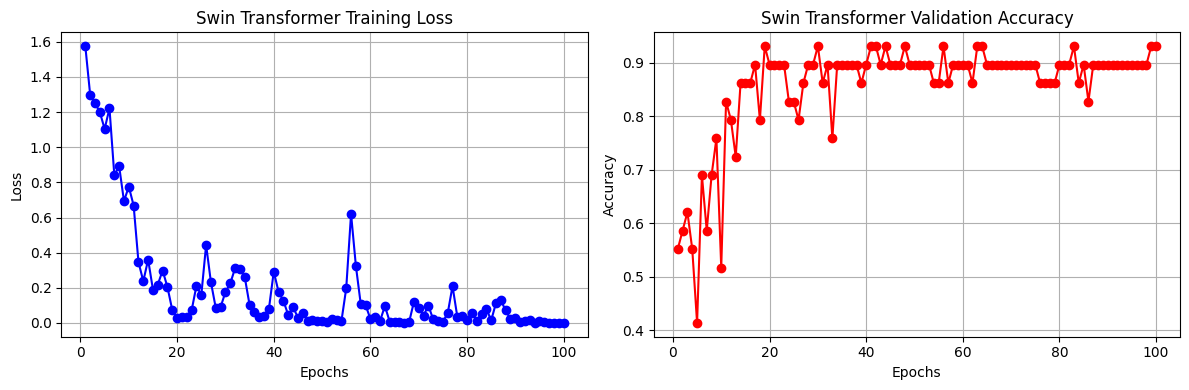

In [30]:
import matplotlib.pyplot as plt

def plot_training_history(history, model_name):
    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(12, 4))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], 'bo-', label='Train Loss')
    plt.title(f'{model_name} Training Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.grid(True)

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['val_acc'], 'ro-', label='Val Acc')
    plt.title(f'{model_name} Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# Plot histories for VGG16, ViT, and Swin
if 'vgg_history' in globals():
    plot_training_history(vgg_history, 'VGG16')
if 'vit_history' in globals():
    plot_training_history(vit_history, 'ViT')
if 'swin_history' in globals():
    plot_training_history(swin_history, 'Swin Transformer')

In [31]:
import torch
import torch.nn as nn
import torchvision.models as models
import timm

class VGGFeatureExtractor(nn.Module):
    def __init__(self, proj_dim=256, pretrained=True):
        super().__init__()
        # Load VGG16 with weights
        weights = models.VGG16_Weights.DEFAULT if pretrained else None
        vgg = models.vgg16(weights=weights)

        # Keep only the feature extraction convolutional backbone
        self.features = vgg.features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # Project 512-dimensional output down to standard projection dimension
        self.projection = nn.Sequential(
            nn.Linear(512, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.projection(x)
        return x

class SwinFeatureExtractor(nn.Module):
    def __init__(self, proj_dim=256, model_name='swin_tiny_patch4_window7_224', pretrained=True):
        super().__init__()
        # Load Hierarchical Swin Transformer
        self.swin = timm.create_model(model_name, pretrained=pretrained, num_classes=0)
        num_features = self.swin.num_features

        # Project hierarchical features down to projection dimension
        self.projection = nn.Sequential(
            nn.Linear(num_features, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU()
        )

    def forward(self, x):
        # timm Swin models return pooled output when num_classes=0
        x = self.swin(x)
        x = self.projection(x)
        return x

class HybridVGGSwinClassifier(nn.Module):
    def __init__(self, num_classes=7, proj_dim=256, dropout_rate=0.4, pretrained=True):
        super().__init__()
        self.vgg_branch = VGGFeatureExtractor(proj_dim=proj_dim, pretrained=pretrained)
        self.swin_branch = SwinFeatureExtractor(proj_dim=proj_dim, pretrained=pretrained)

        # Combined concatenated feature dimension is 2 * proj_dim
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(2 * proj_dim, num_classes)
        )

    def forward(self, x):
        vgg_feats = self.vgg_branch(x)
        swin_feats = self.swin_branch(x)

        # Feature Fusion
        fused_feats = torch.cat((vgg_feats, swin_feats), dim=1)
        logits = self.classifier(fused_feats)
        return logits

# --- SMOKE TEST ---
if __name__ == '__main__':
    print("Running smoke test on Hybrid Network...")
    test_batch = torch.randn(2, 3, 224, 224)
    hybrid_model = HybridVGGSwinClassifier(num_classes=7, proj_dim=256, pretrained=False)
    outputs = hybrid_model(test_batch)
    print("Output shape:", list(outputs.shape))
    assert list(outputs.shape) == [2, 7], "Verification failed! Shape mismatch."
    print("Smoke test passed successfully!")

Running smoke test on Hybrid Network...
Output shape: [2, 7]
Smoke test passed successfully!


In [39]:
import copy
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import f1_score

# --- 1. Re-split Dataset into Train, Val, and Test Splits Stratified ---
print("Re-splitting dataset into Train, Val, and Test set...")
train_val_paths, test_paths, train_val_labels, test_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.15,
    random_state=42,
    stratify=all_labels
)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_val_paths,
    train_val_labels,
    test_size=0.176, # 0.15 / 0.85 approx 17.6% to get a 70/15/15 split
    random_state=42,
    stratify=train_val_labels
)

# Re-create Dataset and Loaders
train_dataset = BlastocystDataset(train_paths, transform=train_transform, class_to_idx=class_to_idx)
val_dataset = BlastocystDataset(val_paths, transform=test_transform, class_to_idx=class_to_idx)
test_dataset = BlastocystDataset(test_paths, transform=test_transform, class_to_idx=class_to_idx)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=2)

print(f"Dataset Splitted: Train={len(train_dataset)}, Val={len(val_dataset)}, Test={len(test_dataset)}")

def train_hybrid_model_configured(model, train_loader, val_loader, class_weights):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # ==========================================
    # STAGE 1: Freeze Backbones Only (Projection & Head Stay Trainable)
    # ==========================================
    print("\n--- STAGE 1: Training Projections + Classifier Head (LR = 1e-4) ---")

    # Freeze Pretrained Backbones
    for param in model.vgg_branch.features.parameters():
        param.requires_grad = False
    for param in model.swin_branch.swin.parameters():
        param.requires_grad = False

    # Unfreeze Custom Projection Layers & Classifier Head
    for param in model.vgg_branch.projection.parameters():
        param.requires_grad = True
    for param in model.swin_branch.projection.parameters():
        param.requires_grad = True
    for param in model.classifier.parameters():
        param.requires_grad = True

    optimizer_stage1 = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=1e-4,
        weight_decay=1e-4
    )

    for epoch in range(15):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer_stage1.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer_stage1.step()
            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)
        val_acc, val_true, val_pred = evaluate_model(model, val_loader)
        val_f1 = f1_score(val_true, val_pred, average='macro', zero_division=0)
        print(f"[Stage 1] Epoch [{epoch+1}/15] - Train Loss: {train_loss:.4f}, Val Acc: {val_acc:.4f}, Val Macro-F1: {val_f1:.4f}")

    # ==========================================
    # STAGE 2: Joint Fine-Tuning (Per-Group LRs + Scheduler)
    # ==========================================
    print("\n--- STAGE 2: Joint Fine-Tuning (Backbones LR = 1e-5, Projection & Head LR = 1e-4) ---")
    for param in model.parameters():
        param.requires_grad = True

    # Setup target parameter groups with separate learning rates
    optimizer_groups = [
        {'params': model.vgg_branch.features.parameters(), 'lr': 1e-5},
        {'params': model.swin_branch.swin.parameters(), 'lr': 1e-5},
        {'params': model.vgg_branch.projection.parameters(), 'lr': 1e-4},
        {'params': model.swin_branch.projection.parameters(), 'lr': 1e-4},
        {'params': model.classifier.parameters(), 'lr': 1e-4}
    ]

    optimizer_stage2 = optim.AdamW(optimizer_groups, weight_decay=1e-4)
    scheduler = CosineAnnealingLR(optimizer_stage2, T_max=35, eta_min=1e-6)

    best_f1 = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0
    patience = 10
    history = {'train_loss': [], 'val_acc': [], 'val_f1': []}

    for epoch in range(35):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer_stage2.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer_stage2.step()
            running_loss += loss.item()

        scheduler.step()
        train_loss = running_loss / len(train_loader)
        val_acc, val_true, val_pred = evaluate_model(model, val_loader)
        val_f1 = f1_score(val_true, val_pred, average='macro', zero_division=0)

        history['train_loss'].append(train_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        print(f"[Stage 2] Epoch [{epoch+1}/35] - Train Loss: {train_loss:.4f}, Val Acc: {val_acc:.4f}, Val Macro-F1: {val_f1:.4f}")

        # Checkpoint selection on best Macro F1-score
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs without Macro-F1 improvement.")
                break

    model.load_state_dict(best_model_wts)
    return model, history

# Re-initialize and train
hybrid_clf = HybridVGGSwinClassifier(num_classes=7, proj_dim=128, dropout_rate=0.4, pretrained=True)
hybrid_clf, hybrid_history = train_hybrid_model_configured(
    hybrid_clf,
    train_loader,
    val_loader,
    class_weights=class_weights
)

# Evaluate on final test dataset once model selection is fully complete
final_acc, y_true, y_pred = evaluate_model(hybrid_clf, test_loader)
print(f"\nFinal Test Accuracy of Selection: {final_acc:.4f}")

Re-splitting dataset into Train, Val, and Test set...
Dataset Splitted: Train=98, Val=22, Test=22

--- STAGE 1: Training Projections + Classifier Head (LR = 1e-4) ---
[Stage 1] Epoch [1/15] - Train Loss: 2.0584, Val Acc: 0.2273, Val Macro-F1: 0.1033
[Stage 1] Epoch [2/15] - Train Loss: 1.8411, Val Acc: 0.4545, Val Macro-F1: 0.2333
[Stage 1] Epoch [3/15] - Train Loss: 1.7351, Val Acc: 0.3636, Val Macro-F1: 0.1719
[Stage 1] Epoch [4/15] - Train Loss: 1.7500, Val Acc: 0.3636, Val Macro-F1: 0.1719
[Stage 1] Epoch [5/15] - Train Loss: 1.5482, Val Acc: 0.4091, Val Macro-F1: 0.1824
[Stage 1] Epoch [6/15] - Train Loss: 1.6951, Val Acc: 0.4091, Val Macro-F1: 0.1481
[Stage 1] Epoch [7/15] - Train Loss: 1.5343, Val Acc: 0.4545, Val Macro-F1: 0.2000
[Stage 1] Epoch [8/15] - Train Loss: 1.4408, Val Acc: 0.3636, Val Macro-F1: 0.1742
[Stage 1] Epoch [9/15] - Train Loss: 1.4487, Val Acc: 0.3636, Val Macro-F1: 0.1742
[Stage 1] Epoch [10/15] - Train Loss: 1.4374, Val Acc: 0.5000, Val Macro-F1: 0.3254
[S

Configured Hybrid VGG16 + Swin Transformer Classification Report
              precision    recall  f1-score   support

          AA       0.71      1.00      0.83        12
          AB       1.00      1.00      1.00         1
          BA       0.00      0.00      0.00         2
          BB       0.75      0.60      0.67         5
          BC       0.00      0.00      0.00         1
          CA       0.00      0.00      0.00         0
          CB       0.00      0.00      0.00         1

    accuracy                           0.73        22
   macro avg       0.35      0.37      0.36        22
weighted avg       0.60      0.73      0.65        22



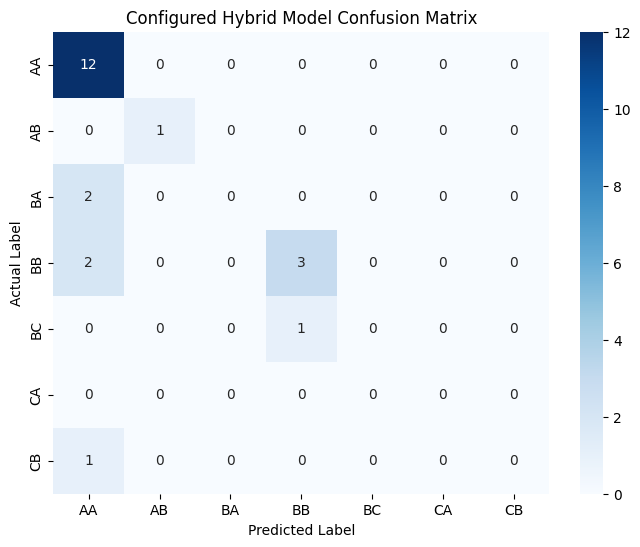

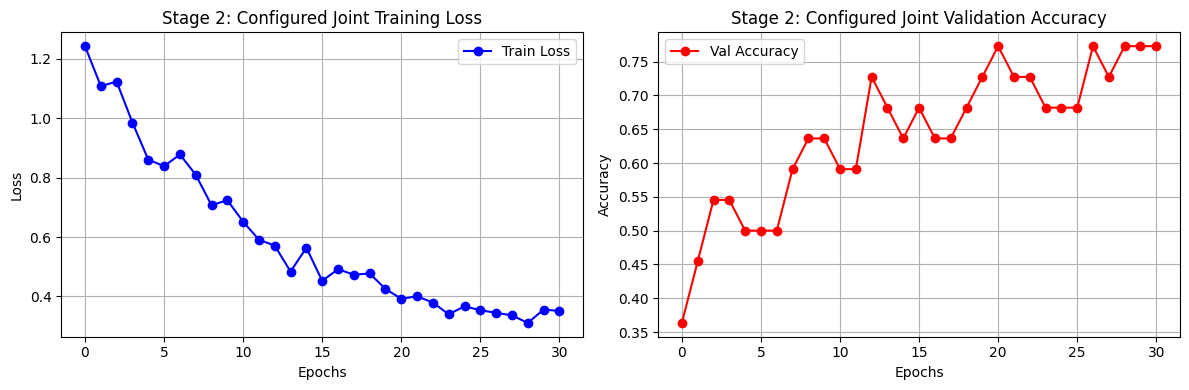

In [40]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Classification Report with the newly trained configured weights
report = classification_report(
    y_true,
    y_pred,
    target_names=VALID_CLASSES,
    labels=range(len(VALID_CLASSES)),
    zero_division=0
)
print("Configured Hybrid VGG16 + Swin Transformer Classification Report")
print(report)

# 2. Confusion Matrix Plot
cm = confusion_matrix(y_true, y_pred, labels=range(len(VALID_CLASSES)))
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=VALID_CLASSES,
    yticklabels=VALID_CLASSES
)
plt.title('Configured Hybrid Model Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# 3. Plot Joint Fine-Tuning Stage Metrics
plt.figure(figsize=(12, 4))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(hybrid_history['train_loss'], 'b-o', label='Train Loss')
plt.title('Stage 2: Configured Joint Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(hybrid_history['val_acc'], 'r-o', label='Val Accuracy')
plt.title('Stage 2: Configured Joint Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score
from sklearn.preprocessing import label_binarize

def get_predictions_and_probabilities(model, data_loader):
    model.eval()
    model = model.to(device)
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = F.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return np.array(all_labels), np.array(all_preds), np.array(all_probs)

# Extract labels, predictions, and probabilities
y_true_vgg, y_pred_vgg, y_prob_vgg = get_predictions_and_probabilities(vgg_base, test_loader)
y_true_swin, y_pred_swin, y_prob_swin = get_predictions_and_probabilities(swin_base, test_loader)
y_true_hybrid, y_pred_hybrid, y_prob_hybrid = get_predictions_and_probabilities(hybrid_clf, test_loader)

# Define metric extractor that filters empty classes for ROC-AUC calculation
def compute_metrics_filtered(y_true, y_pred, y_probs):
    # Precision, Recall, Macro F1 on all present targets
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )

    # Identify which classes actually exist in this test split
    present_classes = np.unique(y_true)
    num_classes_present = len(present_classes)

    if num_classes_present > 1:
        # Keep probabilities only for the present classes and re-normalize them
        y_probs_filtered = y_probs[:, present_classes]
        y_probs_filtered = y_probs_filtered / y_probs_filtered.sum(axis=1, keepdims=True)

        # Binarize targets restricted to present classes
        y_true_binarized = label_binarize(y_true, classes=present_classes)
        if num_classes_present == 2:
            # Binary fallback requires single column of probabilities
            auc = roc_auc_score(y_true_binarized, y_probs_filtered[:, 1], average='macro')
        else:
            auc = roc_auc_score(y_true_binarized, y_probs_filtered, multi_class='ovr', average='macro')
    else:
        auc = np.nan

    return {
        'Precision (Macro)': precision,
        'Recall (Macro)': recall,
        'Macro F1': f1,
        'ROC-AUC (Macro)': auc
    }

vgg_metrics = compute_metrics_filtered(y_true_vgg, y_pred_vgg, y_prob_vgg)
swin_metrics = compute_metrics_filtered(y_true_swin, y_pred_swin, y_prob_swin)
hybrid_metrics = compute_metrics_filtered(y_true_hybrid, y_pred_hybrid, y_prob_hybrid)

# Print metrics comparison table
import pandas as pd
comparison_df = pd.DataFrame({
    'VGG16 Baseline': vgg_metrics,
    'Swin-Tiny Baseline': swin_metrics,
    'Configured Hybrid': hybrid_metrics
}).T
display(comparison_df)

,Precision (Macro),Recall (Macro),Macro F1,ROC-AUC (Macro)
VGG16 Baseline,0.290476,0.391667,0.326496,0.895857
Swin-Tiny Baseline,0.450980,0.400000,0.399836,0.869421
Configured Hybrid,0.409314,0.433333,0.415709,0.876646


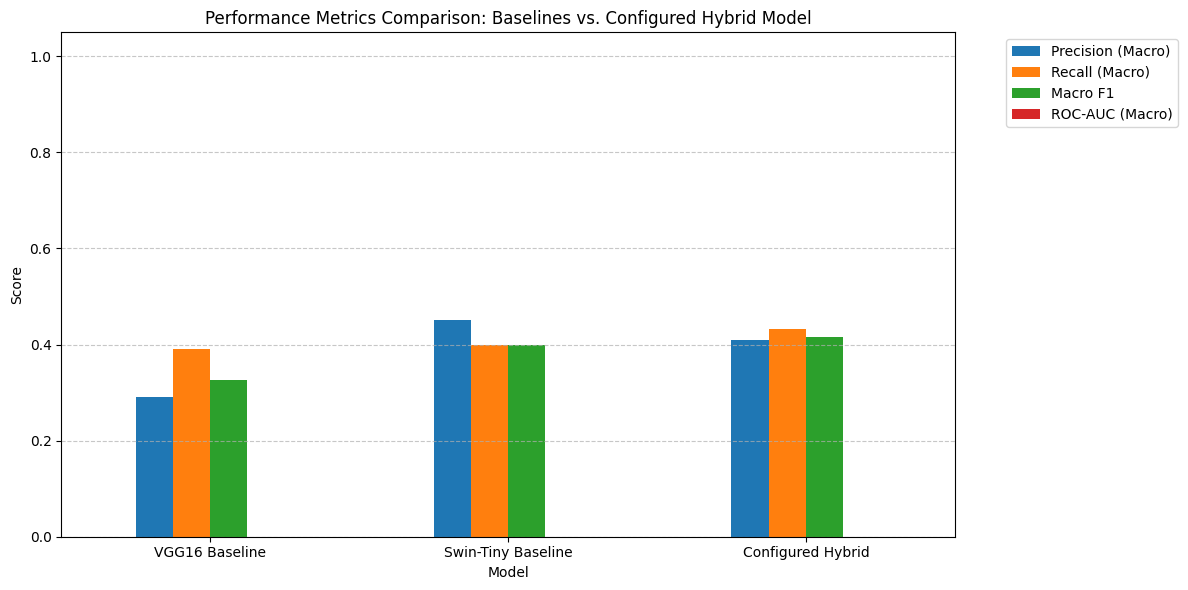

In [43]:
# Visualization of metric comparison
ax = comparison_df.plot(kind='bar', figsize=(12, 6))
plt.title('Performance Metrics Comparison: Baselines vs. Configured Hybrid Model')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

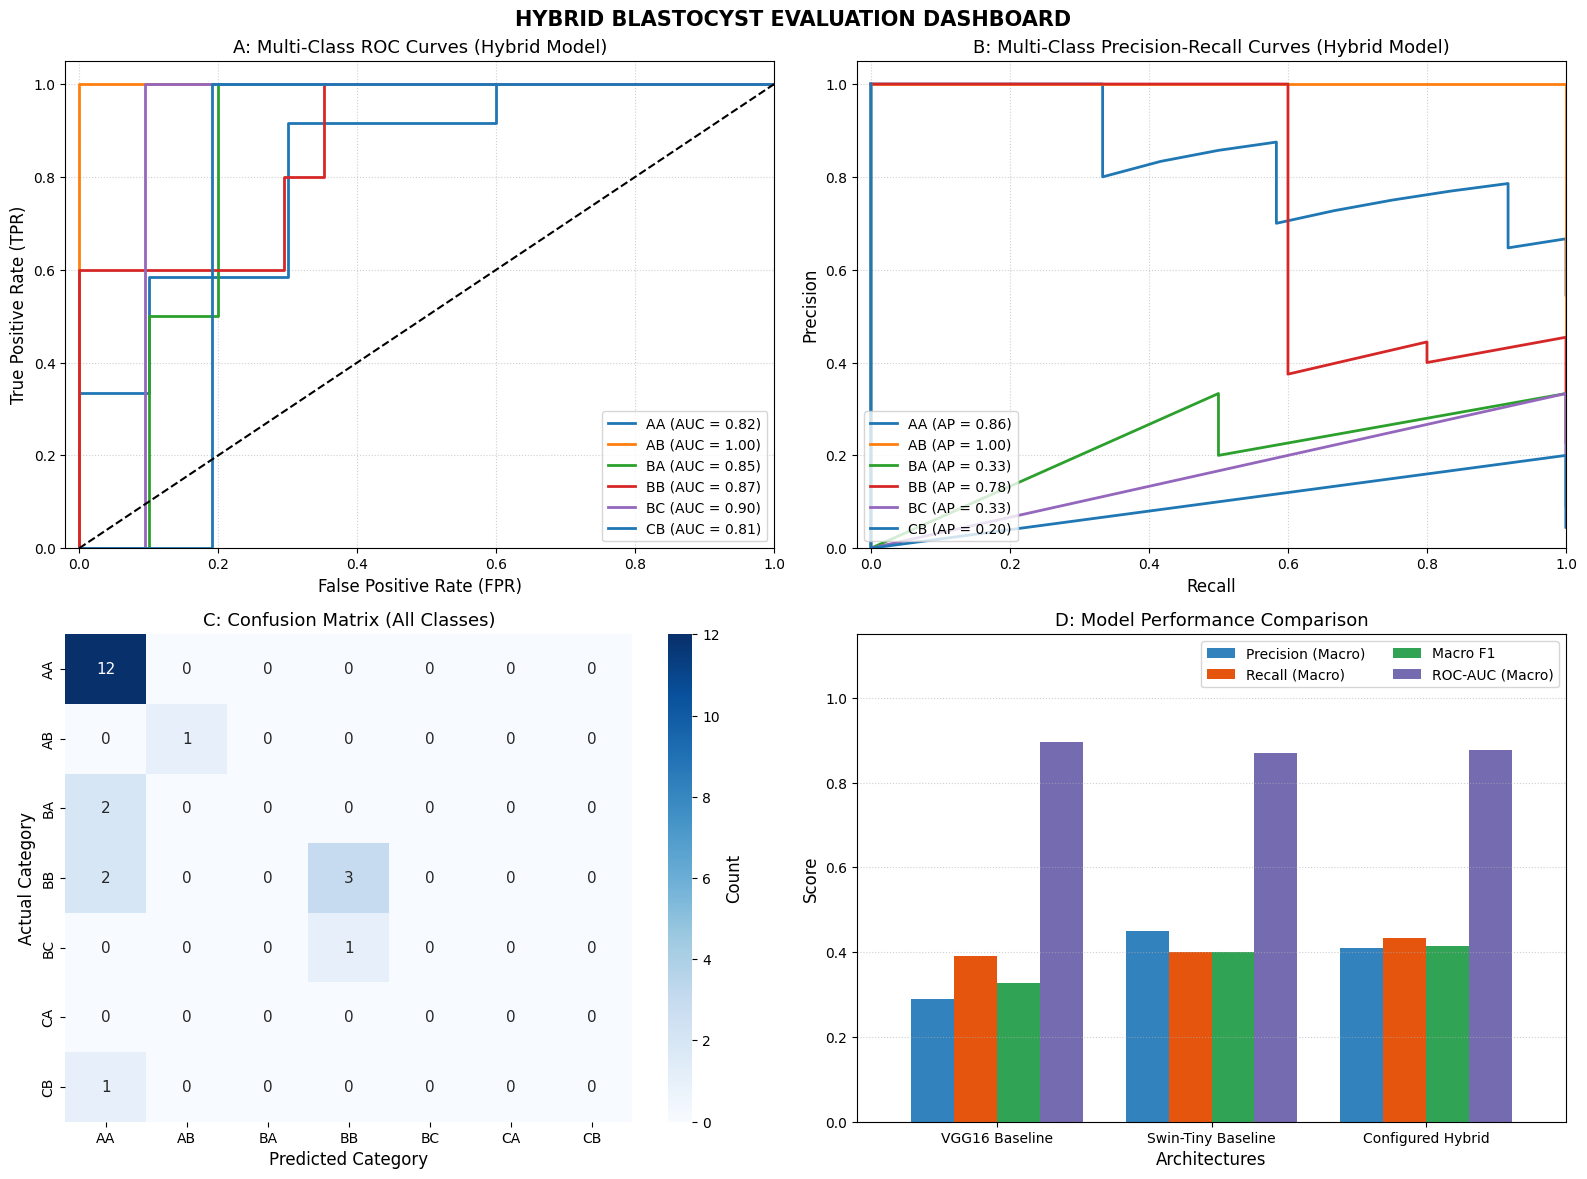

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Configure publication-quality plot aesthetics
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 15
})

# Filter classes present in the test set to ensure robust metric plotting
present_indices = np.unique(y_true)
present_classes = [VALID_CLASSES[i] for i in present_indices]
num_classes_present = len(present_indices)

# Binarize labels for curves
y_true_binarized = label_binarize(y_true, classes=present_indices)
# Normalize probabilities for present classes
y_prob_filtered = y_prob_hybrid[:, present_indices]
y_prob_filtered = y_prob_filtered / y_prob_filtered.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

# -----------------------------------------------------
# Panel A: ROC Curves (One-vs-Rest)
# -----------------------------------------------------
ax_roc = axes[0, 0]
for i, (idx, class_name) in enumerate(zip(present_indices, present_classes)):
    fpr, tpr, _ = roc_curve(y_true_binarized[:, i], y_prob_filtered[:, i])
    roc_auc = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, color=colors[i % len(colors)], lw=2,
                label=f'{class_name} (AUC = {roc_auc:.2f})')

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1.5)
ax_roc.set_xlim([-0.02, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel('False Positive Rate (FPR)')
ax_roc.set_ylabel('True Positive Rate (TPR)')
ax_roc.set_title('A: Multi-Class ROC Curves (Hybrid Model)')
ax_roc.legend(loc="lower right")
ax_roc.grid(True, linestyle=':', alpha=0.6)

# -----------------------------------------------------
# Panel B: Precision-Recall Curves
# -----------------------------------------------------
ax_pr = axes[0, 1]
for i, (idx, class_name) in enumerate(zip(present_indices, present_classes)):
    precision, recall, _ = precision_recall_curve(y_true_binarized[:, i], y_prob_filtered[:, i])
    ap = average_precision_score(y_true_binarized[:, i], y_prob_filtered[:, i])
    ax_pr.plot(recall, precision, color=colors[i % len(colors)], lw=2,
               label=f'{class_name} (AP = {ap:.2f})')

ax_pr.set_xlim([-0.02, 1.0])
ax_pr.set_ylim([0.0, 1.05])
ax_pr.set_xlabel('Recall')
ax_pr.set_ylabel('Precision')
ax_pr.set_title('B: Multi-Class Precision-Recall Curves (Hybrid Model)')
ax_pr.legend(loc="lower left")
ax_pr.grid(True, linestyle=':', alpha=0.6)

# -----------------------------------------------------
# Panel C: Confusion Matrix Heatmap
# -----------------------------------------------------
ax_cm = axes[1, 0]
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=VALID_CLASSES,
    yticklabels=VALID_CLASSES,
    ax=ax_cm,
    cbar_kws={'label': 'Count'}
)
ax_cm.set_title('C: Confusion Matrix (All Classes)')
ax_cm.set_ylabel('Actual Category')
ax_cm.set_xlabel('Predicted Category')

# -----------------------------------------------------
# Panel D: Grouped Model Comparison
# -----------------------------------------------------
ax_comp = axes[1, 1]
comparison_df.plot(kind='bar', ax=ax_comp, width=0.8, color=['#3182bd', '#e6550d', '#31a354', '#756bb1'])
ax_comp.set_title('D: Model Performance Comparison')
ax_comp.set_ylabel('Score')
ax_comp.set_xlabel('Architectures')
ax_comp.set_ylim(0, 1.15)
ax_comp.set_xticklabels(comparison_df.index, rotation=0)
ax_comp.legend(loc='upper right', ncol=2)
ax_comp.grid(axis='y', linestyle=':', alpha=0.6)

plt.suptitle('HYBRID BLASTOCYST EVALUATION DASHBOARD', weight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [41]:
# Save the trained hybrid model
import torch
import os

os.makedirs("saved_models", exist_ok=True)

save_path = "saved_models/hybrid_blastocyst_model.pth"

torch.save({
    "model_state_dict": hybrid_clf.state_dict(),
    "class_to_idx": class_to_idx,
    "test_accuracy": final_acc,
    "num_classes": 7,
    "proj_dim": 128,
    "dropout_rate": 0.4
}, save_path)

print(f"Model saved successfully at: {save_path}")

Model saved successfully at: saved_models/hybrid_blastocyst_model.pth


In [49]:
import torch

checkpoint = torch.load(
    "saved_models/hybrid_blastocyst_model.pth",
    map_location=device,
    weights_only=True
)

inference_model = HybridVGGSwinClassifier(
    num_classes=7,
    proj_dim=128,
    dropout_rate=0.4,
    pretrained=False
).to(device)

inference_model.load_state_dict(checkpoint["model_state_dict"])
inference_model.eval()

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [50]:
import torch
import random
from PIL import Image
import torch.nn.functional as F
from collections import defaultdict

# 1. Group all available images by their actual grade
grade_to_paths = defaultdict(list)
for path in all_paths:
    grade = extract_grade(path)
    if grade in class_to_idx:
        grade_to_paths[grade].append(path)


selected_test_samples = []
random.seed(42)

for grade in sorted(grade_to_paths.keys()):
    paths = grade_to_paths[grade]
    sampled = random.sample(paths, min(2, len(paths)))
    selected_test_samples.extend(sampled)

print(f"Selected {len(selected_test_samples)} diverse samples (max 2 per grade) for evaluation.\n")

# 3. Perform inference
print("=== BALANCED SAMPLE PREDICTIONS ===\n")
for path in selected_test_samples:
    filename = os.path.basename(path)
    true_grade = extract_grade(path)

    # Load and preprocess image
    image = Image.open(path).convert('RGB')
    input_tensor = test_transform(image).unsqueeze(0).to(device)

    # Run inference
    with torch.no_grad():
        outputs = inference_model(input_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, dim=0)
        predicted_grade = idx_to_class[predicted_idx.item()]

    print(f"File: {filename}")
    print(f"-> Ground Truth: {true_grade}")
    print(f"-> Model Prediction: {predicted_grade} ({confidence.item()*100:.2f}% Confidence)")
    print("-" * 50)

Selected 14 diverse samples (max 2 per grade) for evaluation.

=== BALANCED SAMPLE PREDICTIONS ===

File: GRD_AA_547 (1).jpeg
-> Ground Truth: AA
-> Model Prediction: AA (62.28% Confidence)
--------------------------------------------------
File: GRD_AA_555.jpeg
-> Ground Truth: AA
-> Model Prediction: AA (49.08% Confidence)
--------------------------------------------------
File: AB.jpeg
-> Ground Truth: AB
-> Model Prediction: AB (70.08% Confidence)
--------------------------------------------------
File: AB (3).jpeg
-> Ground Truth: AB
-> Model Prediction: AB (66.25% Confidence)
--------------------------------------------------
File: GRD_BA_558.jpeg
-> Ground Truth: BA
-> Model Prediction: BA (83.47% Confidence)
--------------------------------------------------
File: GRD-BA-456.jpeg
-> Ground Truth: BA
-> Model Prediction: AA (45.84% Confidence)
--------------------------------------------------
File: GRD_BB_414.jpeg
-> Ground Truth: BB
-> Model Prediction: AA (65.20% Confidence)
